# Entraînement et test de différents modèles

### Préparation des données :

##### Import des librairies :

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score, validation_curve, RandomizedSearchCV, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, AdaBoostClassifier
from scipy.stats import randint, uniform, loguniform
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC

##### Chargement des données d'entrainement et de test brutes :

In [2]:
data_train = pd.read_csv("train.csv")
data_test = pd.read_csv("test.csv")

##### Feature engineering sur les variables contenant des NaN (cf Classification_1) : 

Concernant la variable `co-applicant_age` :

In [3]:
data_train["has_coapplicant"] = data_train["co-applicant_age"].notnull().astype(int)
data_test["has_coapplicant"] = data_test["co-applicant_age"].notnull().astype(int)

Concernant les variables continues :

In [4]:
# 1) Tranches en texte -> valeurs numériques (milieu de chaque tranche)
dti_tranches = {
    "<20%": 15, "20%-<30%": 25, "30%-<36%": 33,
    "50%-60%": 55, ">60%": 65,
}

data_train["debt_to_income_ratio"] = data_train["debt_to_income_ratio"].replace(dti_tranches)
data_test["debt_to_income_ratio"] = data_test["debt_to_income_ratio"].replace(dti_tranches)

for df in (data_train, data_test):
    df["debt_to_income_ratio"] = pd.to_numeric(df["debt_to_income_ratio"], errors="coerce")

# 2) Pour chaque colonne numérique : conversion, indicateur de manquant, médiane
num_cols = ["income", "property_value", "loan_term", "loan_to_value_ratio",
            "debt_to_income_ratio", "total_units"]

for col in num_cols:
    data_train[col + "_missing"] = data_train[col].isnull().astype(int)  # 1) on note les manquants
    data_train[col] = data_train[col].fillna(data_train[col].median())   # 2) on remplit

for col in num_cols:
    data_test[col + "_missing"] = data_test[col].isnull().astype(int) 
    data_test[col] = data_test[col].fillna(data_train[col].median())   

Concernant les variable catégorielles :

In [5]:
# 1) Colonnes numériques qui sont en fait des codes
code_cols = ["county_code", "applicant_ethnicity-1", "co-applicant_ethnicity-1",
             "applicant_race-1", "co-applicant_race-1"]

# 2) Toutes les colonnes de texte, détectées automatiquement
text_cols = data_train.select_dtypes(exclude="number").columns.tolist()

# 3) Liste finale de toutes les catégorielles, sans doublons
cat_cols = list(dict.fromkeys(text_cols + code_cols))
print(cat_cols)

# 4) NaN -> "Inconnu", puis tout en texte
for df in (data_train, data_test):
    df[cat_cols] = df[cat_cols].astype(object).fillna("Inconnu").astype(str)

# 5) Encodage numérique
encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
data_train[cat_cols] = encoder.fit_transform(data_train[cat_cols])
data_test[cat_cols] = encoder.transform(data_test[cat_cols])

print(data_train.dtypes.value_counts())  # doit n'afficher que int64 / float64

['state_code', 'conforming_loan_limit', 'derived_loan_product_type', 'derived_dwelling_category', 'derived_ethnicity', 'derived_race', 'derived_sex', 'applicant_age', 'co-applicant_age', 'county_code', 'applicant_ethnicity-1', 'co-applicant_ethnicity-1', 'applicant_race-1', 'co-applicant_race-1']
int64      43
float64    22
Name: count, dtype: int64


Vérifications :

In [6]:
data_train.isnull().sum()

id                              0
loan_amount                     0
loan_to_value_ratio             0
property_value                  0
income                          0
                               ..
property_value_missing          0
loan_term_missing               0
loan_to_value_ratio_missing     0
debt_to_income_ratio_missing    0
total_units_missing             0
Length: 65, dtype: int64

In [7]:
data_test.isnull().sum()

id                              0
loan_amount                     0
loan_to_value_ratio             0
property_value                  0
income                          0
                               ..
property_value_missing          0
loan_term_missing               0
loan_to_value_ratio_missing     0
debt_to_income_ratio_missing    0
total_units_missing             0
Length: 64, dtype: int64

##### On sépare les covariables de la variable cible dans les données d'entraînement :

In [8]:
X_train = data_train.drop(columns=["accepted", "id"])
Y_train = data_train["accepted"]
X_test = data_test.drop(columns=["id"])

##### On normalise :

In [9]:
scaler = StandardScaler()
X_train_normed = scaler.fit_transform(X_train)
X_test_normed = scaler.transform(X_test)

## Modèles :

### Arbre de décision : 

##### Entraînement :

`max_depth` est un hyperparamètre qui fixe la profondeur maximale de l’arbre, c’est-à-dire le nombre maximal de questions successives qu’on peut poser avant d’arriver à une prédiction. Pour le choisir, on peut utiliser une courbe de validation. Pour chaque valeur de `max_depth`, on veut savoir comment l’arbre se comporte sur des données qu’il n’a pas vues pendant son entraînement. `validation_curve` automatise cela avec une validation croisée, et renvoie les scores AUC pour qu'on puisse les tracer. On veut évidemment obtenir la plus grande AUC.

Il n'y a pas besoin d'utiliser `X_train_normed` pour les arbres de décision.

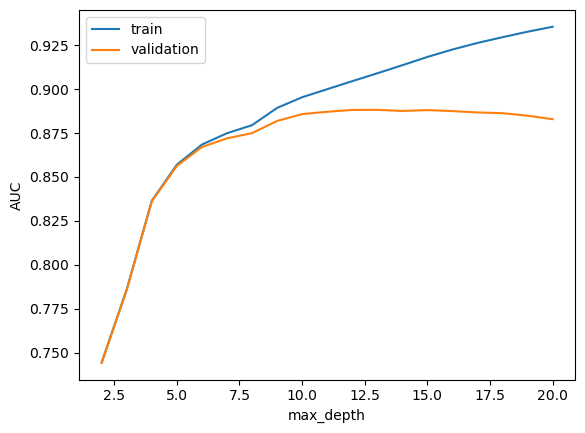

In [11]:
depths = np.arange(2, 21)

train_scores, val_scores = validation_curve(
    DecisionTreeClassifier(class_weight="balanced", min_samples_leaf=50, random_state=42),
    X_train, Y_train,
    param_name="max_depth", param_range=depths,
    cv=5, scoring="roc_auc", n_jobs=-1,
)

plt.plot(depths, train_scores.mean(axis=1), label="train")
plt.plot(depths, val_scores.mean(axis=1), label="validation")
plt.xlabel("max_depth")
plt.ylabel("AUC")
plt.legend()
plt.show()

In [13]:
val_mean = val_scores.mean(axis=1)

i_max = val_mean.argmax()          # indice du maximum

x_max = depths[i_max]              # abscisse (max_depth)
y_max = val_mean[i_max]            # valeur max (AUC)

print(f"Maximum : AUC = {y_max:.4f} pour max_depth = {x_max}")

Maximum : AUC = 0.8882 pour max_depth = 13


In [14]:
model_tree = DecisionTreeClassifier(max_depth=13, random_state=42) 
model_tree.fit(X_train, Y_train)

DecisionTreeClassifier(max_depth=13, random_state=42)

##### Prédictions :

In [15]:
# Probabilité de la classe 1 (accepté)
y_proba = model_tree.predict_proba(X_test)[:, 1]

submission = pd.DataFrame({
    "id": data_test["id"],
    "accepted": y_proba
})

submission.to_csv("submission_decision_tree.csv", index=False)

Sur kaggle, on obtient un score de 0.86841

### Gradient boosting :

##### Entraînement :

Pas besoin de normaliser les données d'entraînement.

In [19]:
model_gdt_boost = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=1000,
    max_leaf_nodes=31,
    min_samples_leaf=50,
    early_stopping=True,
    validation_fraction=0.2,
    n_iter_no_change=50,
    scoring="roc_auc",
    random_state=42,
)
model_gdt_boost.fit(X_train, Y_train)
print("Nombre d'arbres retenu :", model_gdt_boost.n_iter_)

Nombre d'arbres retenu : 250


##### Prédictions :

In [20]:
# Probabilité de la classe 1 (accepté)
y_proba = model_gdt_boost.predict_proba(X_test)[:, 1]

submission = pd.DataFrame({
    "id": data_test["id"],
    "accepted": y_proba
})

submission.to_csv("submission_gradient_boosting_try1.csv", index=False)

Sur kaggle, on obtient un score de 0.91479

##### Pour aller plus loin, on peut faire un réglage des hyperparamètres avec `RandomizedSearchCV` :

In [25]:
# Jeu de validation final, mis de côté
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, Y_train, test_size=0.2, stratify=Y_train, random_state=42
)

base = HistGradientBoostingClassifier(
    max_iter=1000,
    early_stopping=True,
    validation_fraction=0.2,
    n_iter_no_change=50,
    scoring="roc_auc",
    random_state=42,
)

param_dist = {
    "learning_rate":     loguniform(0.03, 0.2),
    "max_leaf_nodes":    randint(8, 64),         # au lieu de 15-256
    "min_samples_leaf":  randint(20, 200),       # au lieu de 20-500
    "l2_regularization": loguniform(1e-3, 10),
    "max_features":      [0.5, 0.7, 0.9, 1.0],
}

search = RandomizedSearchCV(
    base,
    param_distributions=param_dist,
    n_iter=30, cv=3, scoring="roc_auc",
    n_jobs=-1, random_state=42, verbose=2,
)
search.fit(X_tr, y_tr)

print("Meilleur AUC CV :", search.best_score_)
print("Meilleurs paramètres :", search.best_params_)

Fitting 3 folds for each of 30 candidates, totalling 90 fits
Meilleur AUC CV : 0.9118555166592636
Meilleurs paramètres : {'l2_regularization': np.float64(8.568869785189005), 'learning_rate': np.float64(0.07272626471800359), 'max_features': 0.5, 'max_leaf_nodes': 58, 'min_samples_leaf': 154}


On réentraîne avec ces nouveaux hyperparamètres optimaux : 

In [27]:
model_gdt_boost_2 = HistGradientBoostingClassifier(
    max_iter=3000,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=100,
    scoring="roc_auc",
    random_state=42,
    **search.best_params_,
)
model_gdt_boost_2.fit(X_train, Y_train)

print("Meilleurs paramètres :", search.best_params_)
print("Nb d'arbres retenu :", model_gdt_boost_2.n_iter_)

Meilleurs paramètres : {'l2_regularization': np.float64(8.568869785189005), 'learning_rate': np.float64(0.07272626471800359), 'max_features': 0.5, 'max_leaf_nodes': 58, 'min_samples_leaf': 154}
Nb d'arbres retenu : 289


In [28]:
# Probabilité de la classe 1 (accepté)
y_proba = model_gdt_boost_2.predict_proba(X_test)[:, 1]

submission = pd.DataFrame({
    "id": data_test["id"],
    "accepted": y_proba
})

submission.to_csv("submission_gradient_boosting_try2.csv", index=False)

Sur kaggle, on obtient un score de 0.91441

Les deux scores sont équivalents, on passe à un autre modèle.

### SVM à noyau

##### Entraînement

La normalisation est obligatoire. Contrairement aux arbres, le SVM repose sur des distances.

Il y a deux hyperparamètres clefs : 

1) `C` : compromis marge large / erreurs tolérées. `C` petit = frontière lisse, plus d’erreurs tolérées ; `C` grand = le modèle cherche à bien classer chaque point d’entraînement (risque de surapprentissage).
2) `gamma` : portée d’influence d’un point. `gamma` grand = influence très locale, frontière très découpée (surapprentissage) ; `gamma` petit = frontière très lisse (sous-apprentissage).

`C` va de 0,1 à 100 et `gamma` de 1e-4 à 1.
On peut les régler par recherche aléatoire sur un sous-échantillon (pourquoi un sous echantillon ? pcq SVM est très lent):

In [33]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, Y_train, test_size=0.2, stratify=Y_train, random_state=42
)

# Sous-échantillon stratifié de 15 000 lignes (pour garder la proportion accordé/refusé) 
X_sub, _, y_sub, _ = train_test_split(
    X_tr, y_tr, train_size=15_000, stratify=y_tr, random_state=0
)

pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", class_weight="balanced", cache_size=1000)),
])

param_dist = {
    "svm__C":     loguniform(0.1, 100),
    "svm__gamma": loguniform(1e-4, 1),
}

search_svm = RandomizedSearchCV(
    pipe,
    param_distributions=param_dist,
    n_iter=20, cv=3, scoring="roc_auc",
    n_jobs=-1, random_state=42, verbose=2,
)
search_svm.fit(X_sub, y_sub)

print("Meilleur AUC CV :", search_svm.best_score_)
print("Meilleurs paramètres :", search_svm.best_params_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Meilleur AUC CV : 0.8441195385904748
Meilleurs paramètres : {'svm__C': np.float64(0.8179499475211672), 'svm__gamma': np.float64(0.012561043700013555)}


In [ ]:
model_svm = SVC(kernel="rbf", C=0.8179499475211672, gamma=0.012561043700013555, class_weight="balanced")
model_svm.fit(X_train_normed, Y_train)

In [ ]:
# Probabilité de la classe 1 (accepté)
y_proba = model_svm.predict_proba(X_test_normed)[:, 1]

submission = pd.DataFrame({
    "id": data_test["id"],
    "accepted": y_proba
})

submission.to_csv("submission_svm.csv", index=False)

### BDT (Boosted Decision Trees) :

Un BDT est un ensemble d’arbres de décision construits séquentiellement, où chaque nouvel arbre cherche à corriger les erreurs commises par les précédents. La prédiction finale est une combinaison pondérée de tous les arbres.

Boosting : Au lieu d’entraîner les arbres indépendamment (comme dans une random forest), on les entraîne l’un après l’autre, chacun se concentrant sur ce que les précédents ratent.

Il y a deux grandes variantes : Adaboost et Gradient boosting 

On doit régler 3 paramètres : `n_estimators`, `learning_rate` et `max_depth`

In [10]:
grid = GridSearchCV(
    AdaBoostClassifier(estimator=DecisionTreeClassifier(), random_state=42),
    param_grid={
        "estimator__max_depth": [1, 2, 3],
        "n_estimators": [100, 300, 500],
        "learning_rate": [0.1, 0.5, 1.0],
    },
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
)
grid.fit(X_train, Y_train)
print(grid.best_params_, grid.best_score_)

KeyboardInterrupt: 

In [ ]:
# Apprenant faible : un arbre peu profond (souvent une "souche", max_depth=1)
base = DecisionTreeClassifier(max_depth=2)

model_adaboost = AdaBoostClassifier(
    estimator=base,        # s'appelait base_estimator avant sklearn 1.2
    n_estimators=200,
    learning_rate=0.5,
    random_state=42,
)

model_adaboost.fit(X_train, y_train)

### MLP :

### Feature engineering ?